# 05. Final Analysis

## 1. Introduction

Final Analysis is the last analytical stage of the project.

In this notebook, the results of data exploration, data cleaning, sentiment analysis, and theme analysis are examined to generate meaningful business insights.

The main objective is to summarize customer feedback patterns, evaluate customer sentiment, identify major concerns, and support data-driven business decisions.

The analysis uses the processed sentiment analysis and theme analysis datasets generated in the previous notebooks.

In [1]:
# Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Identify project directory

current_path = Path.cwd()
PROJECT_ROOT = None

for path in [current_path, *current_path.parents]:
    if (path / "data").is_dir() and (path / "notebooks").is_dir():
        PROJECT_ROOT = path
        break

if PROJECT_ROOT is None:
    raise FileNotFoundError("Project folder not found.")

# Define processed data directory

PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"

# Load sentiment analysis results

sentiment_file = PROCESSED_DIR / "sentiment_analysis_results.csv"
final_sentiment_df = pd.read_csv(sentiment_file, low_memory=False)

# Load theme analysis results

theme_file = PROCESSED_DIR / "theme_analysis_results.csv"
final_theme_df = pd.read_csv(theme_file, low_memory=False)

print("Final Analysis datasets loaded successfully!")

print("\nSentiment Analysis Dataset Shape:",
      final_sentiment_df.shape)

print("Theme Analysis Dataset Shape:",
      final_theme_df.shape)

print("\nSentiment Analysis Sample:")
display(final_sentiment_df.head())

print("\nTheme Analysis Sample:")
display(final_theme_df.head())

Final Analysis datasets loaded successfully!

Sentiment Analysis Dataset Shape: (28332, 29)
Theme Analysis Dataset Shape: (28332, 7)

Sentiment Analysis Sample:


,id,dateAdded,dateUpdated,name,asins,brand,categories,primaryCategories,imageURLs,keys,...,reviews.title,reviews.username,sourceURLs,review_text_clean,review_date,vader_negative,vader_neutral,vader_positive,sentiment_score,sentiment_label
0,AVpgNzjwLJeJML43Kpxn,2015-10-30T08:59:32Z,2019-04-25T09:08:16Z,AmazonBasics AAA Performance Alkaline Batterie...,"B00QWO9P0O,B00LH3DMUO",Amazonbasics,"AA,AAA,Health,Electronics,Health & Household,C...",Health & Beauty,https://images-na.ssl-images-amazon.com/images...,"amazonbasics/hl002619,amazonbasicsaaaperforman...",...,... 3 of them and one of the item is bad quali...,Byger yang,"https://www.barcodable.com/upc/841710106442,ht...",i order 3 of them and one of the item is bad q...,2017-03-02 00:00:00+00:00,0.186,0.814,0.000,-0.6908,Negative
1,AVpgNzjwLJeJML43Kpxn,2015-10-30T08:59:32Z,2019-04-25T09:08:16Z,AmazonBasics AAA Performance Alkaline Batterie...,"B00QWO9P0O,B00LH3DMUO",Amazonbasics,"AA,AAA,Health,Electronics,Health & Household,C...",Health & Beauty,https://images-na.ssl-images-amazon.com/images...,"amazonbasics/hl002619,amazonbasicsaaaperforman...",...,... always the less expensive way to go for pr...,ByMG,"https://www.barcodable.com/upc/841710106442,ht...",bulk is always the less expensive way to go fo...,2016-08-31 00:00:00+00:00,0.000,0.828,0.172,0.3612,Positive
2,AVpgNzjwLJeJML43Kpxn,2015-10-30T08:59:32Z,2019-04-25T09:08:16Z,AmazonBasics AAA Performance Alkaline Batterie...,"B00QWO9P0O,B00LH3DMUO",Amazonbasics,"AA,AAA,Health,Electronics,Health & Household,C...",Health & Beauty,https://images-na.ssl-images-amazon.com/images...,"amazonbasics/hl002619,amazonbasicsaaaperforman...",...,... are not Duracell but for the price i am ha...,BySharon Lambert,"https://www.barcodable.com/upc/841710106442,ht...",well they are not duracell but for the price i...,2016-12-06 00:00:00+00:00,0.000,0.577,0.423,0.7650,Positive
3,AVpgNzjwLJeJML43Kpxn,2015-10-30T08:59:32Z,2019-04-25T09:08:16Z,AmazonBasics AAA Performance Alkaline Batterie...,"B00QWO9P0O,B00LH3DMUO",Amazonbasics,"AA,AAA,Health,Electronics,Health & Household,C...",Health & Beauty,https://images-na.ssl-images-amazon.com/images...,"amazonbasics/hl002619,amazonbasicsaaaperforman...",...,... as well as name brand batteries at a much ...,Bymark sexson,"https://www.barcodable.com/upc/841710106442,ht...",seem to work as well as name brand batteries a...,2016-03-28 00:00:00+00:00,0.000,0.688,0.312,0.6124,Positive
4,AVpgNzjwLJeJML43Kpxn,2015-10-30T08:59:32Z,2019-04-25T09:08:16Z,AmazonBasics AAA Performance Alkaline Batterie...,"B00QWO9P0O,B00LH3DMUO",Amazonbasics,"AA,AAA,Health,Electronics,Health & Household,C...",Health & Beauty,https://images-na.ssl-images-amazon.com/images...,"amazonbasics/hl002619,amazonbasicsaaaperforman...",...,... batteries are very long lasting the price ...,Bylinda,"https://www.barcodable.com/upc/841710106442,ht...",these batteries are very long lasting the pric...,2017-04-22 00:00:00+00:00,0.000,0.687,0.313,0.6249,Positive



Theme Analysis Sample:


,review_text_clean,sentiment_score,sentiment_label,reviews.rating,name,primaryCategories,matched_themes
0,i order 3 of them and one of the item is bad q...,-0.6908,Negative,3,AmazonBasics AAA Performance Alkaline Batterie...,Health & Beauty,Product Quality
1,bulk is always the less expensive way to go fo...,0.3612,Positive,4,AmazonBasics AAA Performance Alkaline Batterie...,Health & Beauty,Price and Value
2,well they are not duracell but for the price i...,0.7650,Positive,5,AmazonBasics AAA Performance Alkaline Batterie...,Health & Beauty,Price and Value
3,seem to work as well as name brand batteries a...,0.6124,Positive,5,AmazonBasics AAA Performance Alkaline Batterie...,Health & Beauty,Price and Value
4,these batteries are very long lasting the pric...,0.6249,Positive,5,AmazonBasics AAA Performance Alkaline Batterie...,Health & Beauty,Price and Value


## 2. Verifying and Combining Analysis Datasets

In this step, the sentiment analysis and theme analysis datasets are verified before combining them.

The review text columns are compared to ensure that both datasets contain the same customer reviews in the same order.

After successful verification, the identified customer feedback themes are added to the sentiment analysis dataset to create a consolidated dataset for final analysis.

In [2]:
# Verify that both datasets contain the same review records

assert len(final_sentiment_df) == len(final_theme_df), \
    "Dataset record counts do not match."

assert (
    final_sentiment_df["review_text_clean"].reset_index(drop=True)
    .equals(
        final_theme_df["review_text_clean"].reset_index(drop=True)
    )
), "Review records or their order do not match."

# Create consolidated final analysis dataset

final_analysis_df = final_sentiment_df.copy()

final_analysis_df["matched_themes"] = (
    final_theme_df["matched_themes"].reset_index(drop=True)
)

print("Dataset verification successful!")
print("Both datasets contain matching review records.")

print("\nFinal Consolidated Dataset Shape:",
      final_analysis_df.shape)

print("\nFinal Dataset Sample:")
display(
    final_analysis_df[
        [
            "review_text_clean",
            "sentiment_score",
            "sentiment_label",
            "reviews.rating",
            "matched_themes"
        ]
    ].head()
)

Dataset verification successful!
Both datasets contain matching review records.

Final Consolidated Dataset Shape: (28332, 30)

Final Dataset Sample:


,review_text_clean,sentiment_score,sentiment_label,reviews.rating,matched_themes
0,i order 3 of them and one of the item is bad q...,-0.6908,Negative,3,Product Quality
1,bulk is always the less expensive way to go fo...,0.3612,Positive,4,Price and Value
2,well they are not duracell but for the price i...,0.7650,Positive,5,Price and Value
3,seem to work as well as name brand batteries a...,0.6124,Positive,5,Price and Value
4,these batteries are very long lasting the pric...,0.6249,Positive,5,Price and Value


## 3. Overall Customer Sentiment Analysis

In this step, the overall distribution of customer sentiment is analyzed using the consolidated dataset.

The total number and percentage of Positive, Negative, and Neutral reviews are calculated.

This analysis provides an overall understanding of customer satisfaction and helps evaluate the general perception of products based on customer feedback.

In [3]:
# Calculate overall customer sentiment distribution

sentiment_summary = (
    final_analysis_df["sentiment_label"]
    .value_counts()
    .reindex(["Positive", "Neutral", "Negative"], fill_value=0)
    .reset_index()
)

sentiment_summary.columns = ["Sentiment", "Review Count"]

sentiment_summary["Percentage"] = (
    sentiment_summary["Review Count"]
    / len(final_analysis_df)
) * 100

print("Overall Customer Sentiment Summary:")
display(sentiment_summary.round(2))

print("\nTotal Customer Reviews:", len(final_analysis_df))

print(
    "Overall Positive Feedback:",
    round(
        sentiment_summary.loc[
            sentiment_summary["Sentiment"] == "Positive",
            "Percentage"
        ].iloc[0],
        2
    ),
    "%"
)

Overall Customer Sentiment Summary:


,Sentiment,Review Count,Percentage
0,Positive,23724,83.74
1,Neutral,2498,8.82
2,Negative,2110,7.45



Total Customer Reviews: 28332
Overall Positive Feedback: 83.74 %


## 4. Visualizing Overall Customer Sentiment

In this step, a pie chart is created to visualize the overall distribution of Positive, Neutral, and Negative customer reviews.

The visualization provides a clear representation of customer sentiment proportions and helps communicate the overall customer perception of the products.

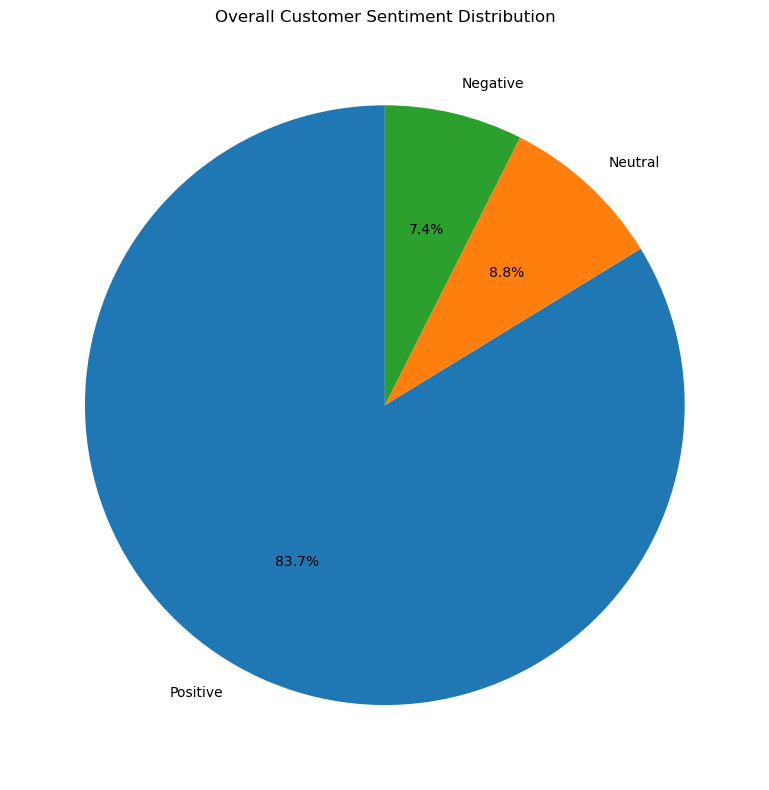

In [4]:
# Visualize overall customer sentiment distribution

plt.figure(figsize=(8, 8))

plt.pie(
    sentiment_summary["Review Count"],
    labels=sentiment_summary["Sentiment"],
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Overall Customer Sentiment Distribution")
plt.tight_layout()
plt.show()

## 5. Sentiment Analysis Based on Product Ratings

In this step, customer sentiment is compared with product ratings ranging from 1 to 5 stars.

A cross-tabulation is created to examine the distribution of Positive, Negative, and Neutral reviews across different rating levels.

This analysis helps understand the relationship between customer ratings and sentiment classification.

In [5]:
# Analyze sentiment distribution across product ratings

rating_sentiment_analysis = pd.crosstab(
    final_analysis_df["reviews.rating"],
    final_analysis_df["sentiment_label"]
)

print("Sentiment Distribution Based on Product Ratings:")
display(rating_sentiment_analysis)

print("\nTotal Records:",
      rating_sentiment_analysis.to_numpy().sum())

Sentiment Distribution Based on Product Ratings:


sentiment_label,Negative,Neutral,Positive
reviews.rating,,,
1,547,164,254
2,255,140,221
3,258,230,718
4,370,429,4849
5,680,1535,17682



Total Records: 28332


## 6. Visualizing Sentiment Across Product Ratings

In this step, a heatmap is created to visualize the relationship between product ratings and customer sentiment.

The heatmap displays the percentage distribution of Positive, Negative, and Neutral sentiment within each rating category.

This visualization helps identify sentiment patterns across different product rating levels.

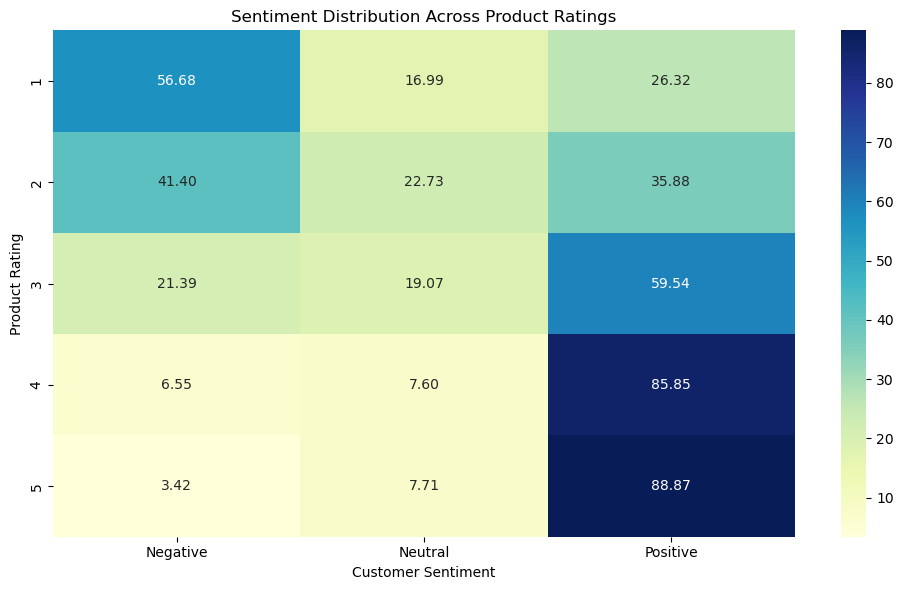

In [6]:
# Calculate row-wise sentiment percentages

rating_sentiment_percentage = (
    rating_sentiment_analysis
    .div(rating_sentiment_analysis.sum(axis=1), axis=0)
) * 100

# Create sentiment heatmap

plt.figure(figsize=(10, 6))

sns.heatmap(
    rating_sentiment_percentage,
    annot=True,
    fmt=".2f",
    cmap="YlGnBu"
)

plt.title("Sentiment Distribution Across Product Ratings")
plt.xlabel("Customer Sentiment")
plt.ylabel("Product Rating")

plt.tight_layout()
plt.show()

## 7. Analyzing Customer Feedback Across Product Categories

In this step, customer reviews are grouped according to their product categories.

The total number of reviews and average product rating are calculated for each category.

This analysis helps identify which product categories receive the highest customer feedback and understand their overall rating performance.

In [2]:
# Recreate category analysis

from pathlib import Path
import pandas as pd

# Locate project directory
current_path = Path.cwd()
PROJECT_ROOT = None

for path in [current_path, *current_path.parents]:
    if (path / "data").is_dir() and (path / "notebooks").is_dir():
        PROJECT_ROOT = path
        break

if PROJECT_ROOT is None:
    raise FileNotFoundError("Project folder not found.")

PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"

# Reload sentiment analysis dataset
final_analysis_df = pd.read_csv(
    PROCESSED_DIR / "sentiment_analysis_results.csv",
    low_memory=False
)

# Recalculate category analysis
category_analysis = (
    final_analysis_df
    .groupby("primaryCategories")
    .agg(
        Total_Reviews=("review_text_clean", "count"),
        Average_Rating=("reviews.rating", "mean")
    )
    .sort_values(
        by="Total_Reviews",
        ascending=False
    )
    .reset_index()
)

category_analysis["Average_Rating"] = (
    category_analysis["Average_Rating"].round(2)
)

print("Category analysis recreated successfully!")
display(category_analysis)

Category analysis recreated successfully!


,primaryCategories,Total_Reviews,Average_Rating
0,Electronics,13995,4.56
1,Health & Beauty,12071,4.45
2,"Toys & Games,Electronics",1676,4.53
3,"Office Supplies,Electronics",386,4.55
4,"Electronics,Media",185,4.66
5,Office Supplies,9,5.00
6,Animals & Pet Supplies,6,4.50
7,"Electronics,Furniture",2,5.00
8,Home & Garden,2,4.50


## 8. Visualizing Customer Feedback by Product Category

In this step, a horizontal bar chart is created to visualize the number of customer reviews across different product categories.

The visualization helps identify the categories that contribute the highest volume of customer feedback.

Categories with very few reviews are also displayed, but their results should be interpreted cautiously.

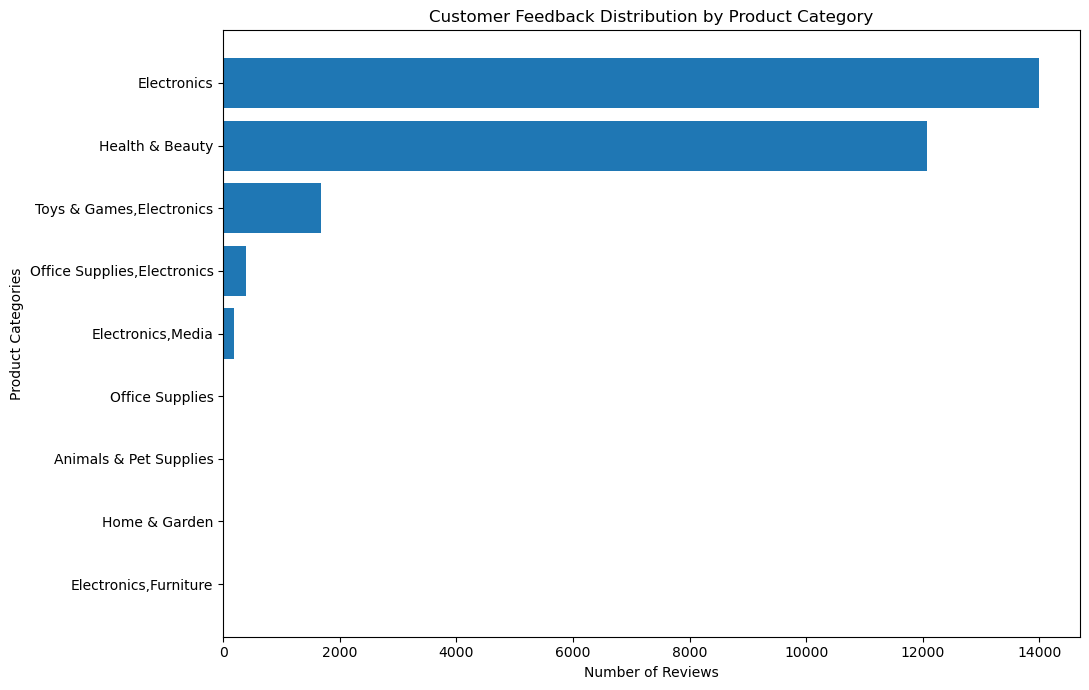

In [4]:
# Import visualization library
import matplotlib.pyplot as plt

# Visualize customer feedback by product category

category_plot = category_analysis.sort_values(
    by="Total_Reviews",
    ascending=True
)

plt.figure(figsize=(11, 7))

plt.barh(
    category_plot["primaryCategories"],
    category_plot["Total_Reviews"]
)

plt.title("Customer Feedback Distribution by Product Category")
plt.xlabel("Number of Reviews")
plt.ylabel("Product Categories")

plt.tight_layout()
plt.show()

## 9. Negative Sentiment Analysis by Product Category

In this step, customer feedback is grouped by product category and sentiment label.

The total number of reviews and negative reviews are calculated for each category.

The negative feedback percentage is also calculated to identify product categories that may require business improvement.

This analysis supports better identification of customer dissatisfaction across product categories.

In [9]:
# Analyze negative feedback by product category

category_sentiment_analysis = (
    final_analysis_df
    .groupby("primaryCategories")
    .agg(
        Total_Reviews=("sentiment_label", "count"),
        Negative_Reviews=(
            "sentiment_label",
            lambda x: (x == "Negative").sum()
        )
    )
)

category_sentiment_analysis["Negative_Percentage"] = (
    category_sentiment_analysis["Negative_Reviews"]
    / category_sentiment_analysis["Total_Reviews"]
) * 100

category_sentiment_analysis = (
    category_sentiment_analysis
    .sort_values(
        by="Negative_Percentage",
        ascending=False
    )
)

print("Negative Feedback Analysis by Product Category:")
display(category_sentiment_analysis.round(2))

Negative Feedback Analysis by Product Category:


,Total_Reviews,Negative_Reviews,Negative_Percentage
primaryCategories,,,
Health & Beauty,12071,1128,9.34
"Office Supplies,Electronics",386,31,8.03
"Toys & Games,Electronics",1676,102,6.09
Electronics,13995,843,6.02
"Electronics,Media",185,6,3.24
Animals & Pet Supplies,6,0,0.00
"Electronics,Furniture",2,0,0.00
Office Supplies,9,0,0.00
Home & Garden,2,0,0.00


## 10. Visualizing Negative Feedback by Product Category

In this step, a horizontal bar chart is created to compare negative sentiment percentages across product categories.

The visualization helps identify categories with a higher proportion of negative customer feedback.

It supports the identification of product categories that may require further investigation and improvement.

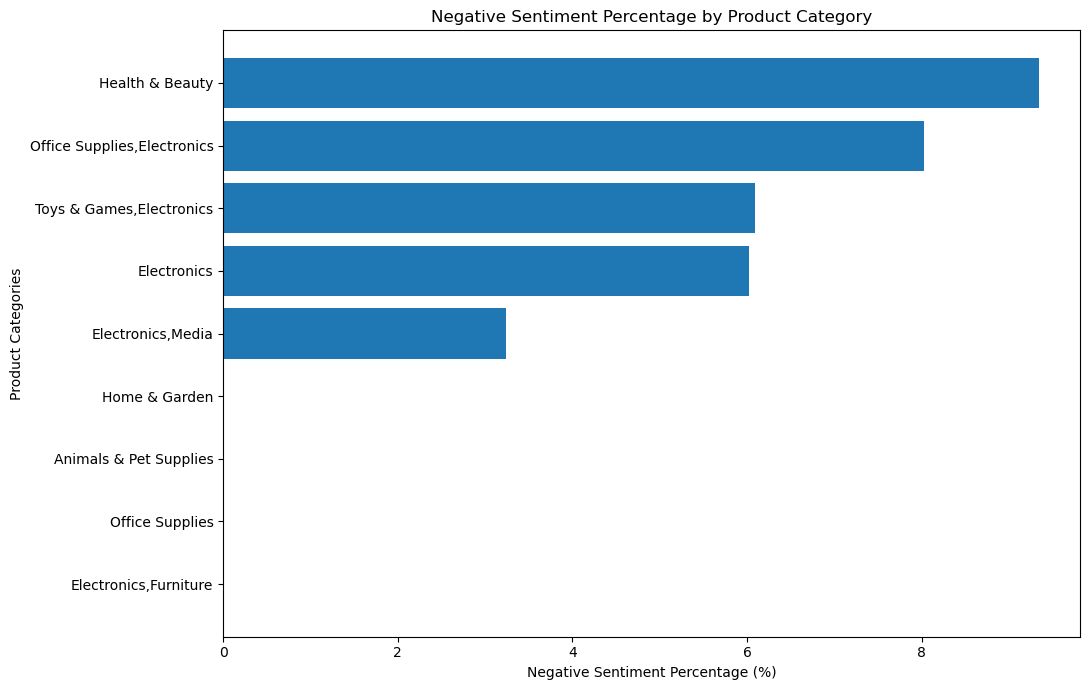

In [8]:
# Visualize negative feedback percentage by product category

category_negative_plot = (
    category_sentiment_analysis
    .sort_values(
        by="Negative_Percentage",
        ascending=True
    )
)

plt.figure(figsize=(11, 7))

plt.barh(
    category_negative_plot.index,
    category_negative_plot["Negative_Percentage"]
)

plt.title("Negative Sentiment Percentage by Product Category")
plt.xlabel("Negative Sentiment Percentage (%)")
plt.ylabel("Product Categories")

plt.tight_layout()
plt.show()

## 11. Overall Customer Rating Analysis

In this step, the overall average product rating is calculated using all customer reviews.

The average rating provides a general indication of customer satisfaction with the products included in the dataset.

The minimum and maximum ratings are also examined to understand the rating range.

In [10]:
# Calculate overall customer rating statistics

overall_average_rating = (
    final_analysis_df["reviews.rating"].mean()
)

minimum_rating = final_analysis_df["reviews.rating"].min()

maximum_rating = final_analysis_df["reviews.rating"].max()

print("Overall Customer Rating Analysis")
print("-----------------------------------")
print("Total Reviews:", len(final_analysis_df))
print("Average Product Rating:", round(overall_average_rating, 2))
print("Minimum Rating:", minimum_rating)
print("Maximum Rating:", maximum_rating)

Overall Customer Rating Analysis
-----------------------------------
Total Reviews: 28332
Average Product Rating: 4.51
Minimum Rating: 1
Maximum Rating: 5


## 12. Average Product Rating by Product Category

In this step, the average customer rating is calculated for each product category.

This analysis helps compare customer satisfaction across different product categories and identify categories with relatively higher or lower average ratings.

In [12]:
# Calculate average product rating by category

category_rating_analysis = (
    final_analysis_df
    .groupby("primaryCategories")
    .agg(
        Total_Reviews=("reviews.rating", "count"),
        Average_Rating=("reviews.rating", "mean")
    )
    .sort_values(
        by="Average_Rating",
        ascending=False
    )
    .reset_index()
)

category_rating_analysis["Average_Rating"] = (
    category_rating_analysis["Average_Rating"].round(2)
)

print("Average Product Rating by Category:")
display(category_rating_analysis)

Average Product Rating by Category:


,primaryCategories,Total_Reviews,Average_Rating
0,"Electronics,Furniture",2,5.00
1,Office Supplies,9,5.00
2,"Electronics,Media",185,4.66
3,Electronics,13995,4.56
4,"Office Supplies,Electronics",386,4.55
5,"Toys & Games,Electronics",1676,4.53
6,Animals & Pet Supplies,6,4.50
7,Home & Garden,2,4.50
8,Health & Beauty,12071,4.45


## 13. Visualizing Average Product Rating by Category

In this step, a horizontal bar chart is created to compare average product ratings across different categories.

The visualization helps identify differences in customer ratings and highlights categories that may require further investigation.

The number of reviews for each category should also be considered while interpreting the average ratings.

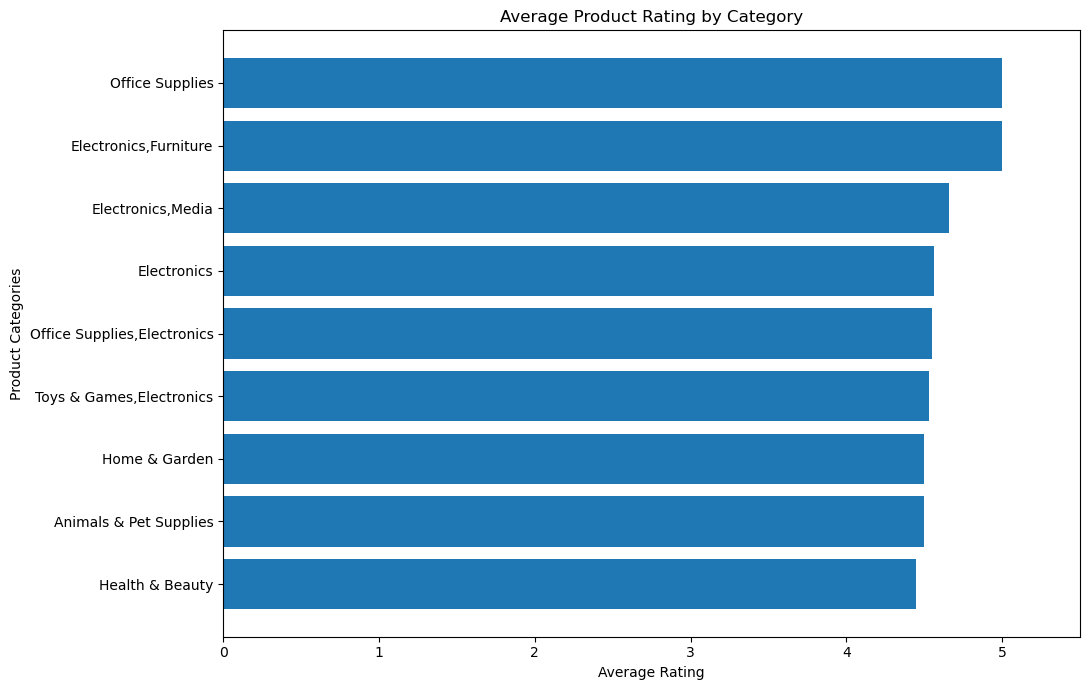

In [13]:
# Visualize average product rating by category

rating_plot = category_rating_analysis.sort_values(
    by="Average_Rating",
    ascending=True
)

plt.figure(figsize=(11, 7))

plt.barh(
    rating_plot["primaryCategories"],
    rating_plot["Average_Rating"]
)

plt.title("Average Product Rating by Category")
plt.xlabel("Average Rating")
plt.ylabel("Product Categories")
plt.xlim(0, 5.5)

plt.tight_layout()
plt.show()

## 14. Identifying High-Priority Negative Customer Feedback

In this step, negative customer reviews are extracted from the consolidated dataset.

The reviews are sorted according to their sentiment scores, with the most negative reviews appearing first.

This analysis helps identify customer complaints that may require immediate attention and supports business decision-making.

In [15]:
# Reload theme analysis results

THEME_FILE = PROCESSED_DIR / "theme_analysis_results.csv"

final_theme_df = pd.read_csv(
    THEME_FILE,
    low_memory=False
)

# Verify that both datasets contain matching reviews

assert final_analysis_df["review_text_clean"].reset_index(drop=True).equals(
    final_theme_df["review_text_clean"].reset_index(drop=True)
), "Review records do not match."

# Restore matched themes

final_analysis_df["matched_themes"] = (
    final_theme_df["matched_themes"].reset_index(drop=True)
)

# Extract negative customer feedback

negative_feedback_df = final_analysis_df[
    final_analysis_df["sentiment_label"] == "Negative"
].copy()

negative_feedback_df = negative_feedback_df.sort_values(
    by="sentiment_score",
    ascending=True
)

print("High-Priority Negative Customer Feedback")
print("---------------------------------------------")
print("Total Negative Reviews:", len(negative_feedback_df))

display(
    negative_feedback_df[
        [
            "review_text_clean",
            "sentiment_score",
            "reviews.rating",
            "primaryCategories",
            "matched_themes"
        ]
    ].head(10)
)

High-Priority Negative Customer Feedback
---------------------------------------------
Total Negative Reviews: 2110


,review_text_clean,sentiment_score,reviews.rating,primaryCategories,matched_themes
6502,amazon seems to have changed the manufacturer ...,-0.9882,2,Health & Beauty,Packaging
25878,"like a lot of reviewers here, i struggled to f...",-0.9881,4,Electronics,Delivery Experience
877,i got two of these batteries with my fire tv s...,-0.9709,1,Health & Beauty,Customer Service
7945,lot's of claims in the description and lots of...,-0.9674,1,Health & Beauty,Other
8817,"bought a, c d 9v batteries in april the aaa se...",-0.9646,1,Health & Beauty,Other
1027,"bought a, c d 9v batteries in april the aaa se...",-0.9646,1,Health & Beauty,Other
8461,worst batteries ever. i thought there would be...,-0.9598,1,Health & Beauty,Product Performance
8815,don't recharge them like seriously don't!!!! t...,-0.9577,3,Health & Beauty,Other
1025,don't recharge them like seriously don't!!!! t...,-0.9577,3,Health & Beauty,Other
25888,can someone explain to me why i can find hundr...,-0.9555,1,Electronics,Product Quality


## 15. Negative Customer Feedback Analysis by Theme

In this step, negative customer reviews are grouped according to their identified feedback themes.

The number of negative reviews associated with each theme is calculated.

This analysis helps identify recurring customer complaints and determine which areas of the customer experience require improvement.

In [16]:
# Analyze negative reviews by customer feedback theme

negative_theme_analysis = (
    negative_feedback_df
    .groupby("matched_themes")
    .size()
    .reset_index(name="Negative_Review_Count")
    .sort_values(
        by="Negative_Review_Count",
        ascending=False
    )
)

print("Negative Customer Feedback by Theme:")
display(negative_theme_analysis)

print(
    "\nTotal Negative Reviews:",
    len(negative_feedback_df)
)

Negative Customer Feedback by Theme:


,matched_themes,Negative_Review_Count
8,Other,1295
10,Price and Value,319
16,Product Performance,145
18,Product Quality,95
14,Price and Value; Product Performance,50
9,Packaging,45
0,Customer Service,28
2,Delivery Experience,28
13,Price and Value; Packaging,18
23,Product Quality; Price and Value,18



Total Negative Reviews: 2110


## 16. Visualizing Negative Customer Feedback by Theme

In this step, a horizontal bar chart is created to visualize the most frequently occurring negative feedback themes.

The top ten theme groups are selected to make the visualization easier to understand.

This visualization helps identify the major areas of customer dissatisfaction and supports business improvement decisions.

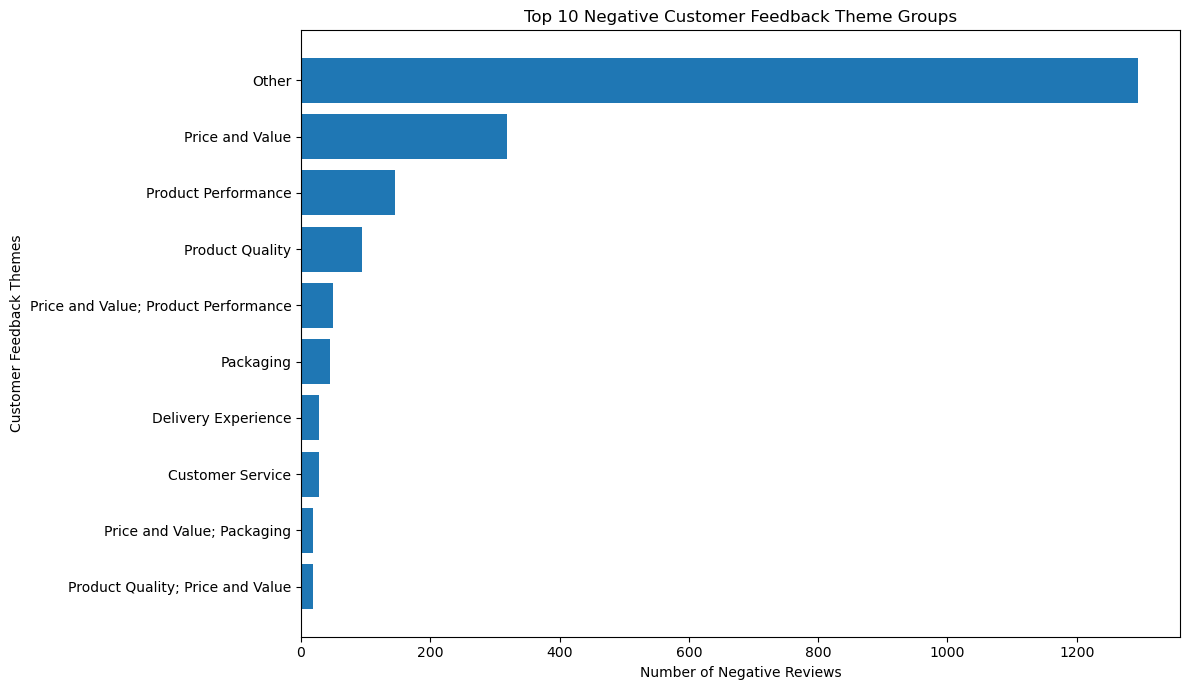

In [17]:
# Visualize top ten negative feedback theme groups

top_negative_themes = (
    negative_theme_analysis
    .head(10)
    .sort_values(
        by="Negative_Review_Count",
        ascending=True
    )
)

plt.figure(figsize=(12, 7))

plt.barh(
    top_negative_themes["matched_themes"],
    top_negative_themes["Negative_Review_Count"]
)

plt.title("Top 10 Negative Customer Feedback Theme Groups")
plt.xlabel("Number of Negative Reviews")
plt.ylabel("Customer Feedback Themes")

plt.tight_layout()
plt.show()

## 17. Generating Final Business Insights

In this step, key business insights are generated from the consolidated customer feedback dataset.

The analysis summarizes overall customer sentiment, negative feedback, product ratings, and customer dissatisfaction.

These insights help businesses understand customer experience and identify areas that require improvement.

In [18]:
# Generate final business insights

total_reviews = len(final_analysis_df)

sentiment_counts = final_analysis_df["sentiment_label"].value_counts()

positive_count = sentiment_counts.get("Positive", 0)
neutral_count = sentiment_counts.get("Neutral", 0)
negative_count = sentiment_counts.get("Negative", 0)

average_rating = final_analysis_df["reviews.rating"].mean()

negative_percentage = (negative_count / total_reviews) * 100
positive_percentage = (positive_count / total_reviews) * 100

print("FINAL BUSINESS INSIGHTS")
print("=" * 50)

print("Total Customer Reviews:", total_reviews)
print("Positive Reviews:", positive_count)
print("Neutral Reviews:", neutral_count)
print("Negative Reviews:", negative_count)

print(f"\nPositive Feedback: {positive_percentage:.2f}%")
print(f"Negative Feedback: {negative_percentage:.2f}%")
print(f"Average Product Rating: {average_rating:.2f} / 5")

print("\nKEY BUSINESS OBSERVATIONS")
print("-" * 50)

print("1. Most customer feedback is positive.")
print("2. Negative feedback requires further investigation.")
print("3. Customer Service has the highest negative sentiment percentage among identified themes.")
print("4. Health & Beauty has the highest negative feedback percentage among product categories.")
print("5. Price and Value is the most frequently discussed identified theme.")

FINAL BUSINESS INSIGHTS
Total Customer Reviews: 28332
Positive Reviews: 23724
Neutral Reviews: 2498
Negative Reviews: 2110

Positive Feedback: 83.74%
Negative Feedback: 7.45%
Average Product Rating: 4.51 / 5

KEY BUSINESS OBSERVATIONS
--------------------------------------------------
1. Most customer feedback is positive.
2. Negative feedback requires further investigation.
3. Customer Service has the highest negative sentiment percentage among identified themes.
4. Health & Beauty has the highest negative feedback percentage among product categories.
5. Price and Value is the most frequently discussed identified theme.


## 18. Business Recommendations

Based on the customer sentiment, theme analysis, and product category analysis, business recommendations are developed to improve customer satisfaction.

The recommendations focus on customer service, product quality, delivery experience, product performance, and customer value.

These recommendations can help businesses prioritize customer-related problems and improve the overall customer experience.

In [19]:
# Generate business recommendations

business_recommendations = [
    {
        "Area": "Customer Service",
        "Finding": "Highest negative sentiment percentage among identified themes (12.12%).",
        "Recommendation": "Improve customer support response time and complaint resolution."
    },
    {
        "Area": "Health & Beauty",
        "Finding": "Highest negative feedback percentage among product categories (9.34%).",
        "Recommendation": "Investigate product-specific complaints and improve product quality checks."
    },
    {
        "Area": "Price and Value",
        "Finding": "Most frequently discussed identified feedback theme (7,679 mentions).",
        "Recommendation": "Review product pricing, affordability, and value-for-money perception."
    },
    {
        "Area": "Delivery Experience",
        "Finding": "Negative feedback is present in delivery-related reviews.",
        "Recommendation": "Monitor shipping delays and improve delivery communication."
    },
    {
        "Area": "Unidentified Feedback",
        "Finding": "1,295 negative reviews belong to the Other theme.",
        "Recommendation": "Expand keyword coverage and investigate unclassified negative reviews."
    }
]

recommendations_df = pd.DataFrame(business_recommendations)

print("BUSINESS RECOMMENDATIONS")
print("=" * 70)

display(recommendations_df)

BUSINESS RECOMMENDATIONS


,Area,Finding,Recommendation
0,Customer Service,Highest negative sentiment percentage among id...,Improve customer support response time and com...
1,Health & Beauty,Highest negative feedback percentage among pro...,Investigate product-specific complaints and im...
2,Price and Value,Most frequently discussed identified feedback ...,"Review product pricing, affordability, and val..."
3,Delivery Experience,Negative feedback is present in delivery-relat...,Monitor shipping delays and improve delivery c...
4,Unidentified Feedback,"1,295 negative reviews belong to the Other theme.",Expand keyword coverage and investigate unclas...


## 19. Exporting Final Analysis Results

In this step, the consolidated customer feedback dataset and business recommendations are exported as CSV files.

These files contain the results of data cleaning, sentiment analysis, theme identification, and final business analysis.

The exported datasets can be used in the next stages of the project, including database integration and dashboard development.

In [20]:
# Export final analysis results

FINAL_DATASET_FILE = PROCESSED_DIR / "final_customer_analysis.csv"
RECOMMENDATIONS_FILE = PROCESSED_DIR / "business_recommendations.csv"

final_analysis_df.to_csv(FINAL_DATASET_FILE, index=False)
recommendations_df.to_csv(RECOMMENDATIONS_FILE, index=False)

print("Final analysis files exported successfully!")
print("\nExported Files:")

print("1.", FINAL_DATASET_FILE.name)
print("2.", RECOMMENDATIONS_FILE.name)

print("\nFinal Dataset Shape:", final_analysis_df.shape)
print("Business Recommendations Shape:", recommendations_df.shape)

Final analysis files exported successfully!

Exported Files:
1. final_customer_analysis.csv
2. business_recommendations.csv

Final Dataset Shape: (28332, 30)
Business Recommendations Shape: (5, 3)


## 20. Verifying Exported Final Analysis Files

In this step, the exported CSV files are loaded again to verify their existence, structure, and data integrity.

The verification ensures that the final customer analysis dataset and business recommendations have been saved correctly and are ready for further project integration.

In [21]:
# Verify exported final analysis files

verified_final_df = pd.read_csv(FINAL_DATASET_FILE, low_memory=False)
verified_recommendations_df = pd.read_csv(RECOMMENDATIONS_FILE)

print("FINAL ANALYSIS FILE VERIFICATION")
print("=" * 55)

print("\n1. Final Customer Analysis")
print("File Exists:", FINAL_DATASET_FILE.exists())
print("Shape:", verified_final_df.shape)
print("Total Records:", len(verified_final_df))

print("\n2. Business Recommendations")
print("File Exists:", RECOMMENDATIONS_FILE.exists())
print("Shape:", verified_recommendations_df.shape)

print("\nFinal Dataset Columns:")
print(verified_final_df.columns.tolist())

print("\nVerification completed successfully!")

FINAL ANALYSIS FILE VERIFICATION

1. Final Customer Analysis
File Exists: True
Shape: (28332, 30)
Total Records: 28332

2. Business Recommendations
File Exists: True
Shape: (5, 3)

Final Dataset Columns:
['id', 'dateAdded', 'dateUpdated', 'name', 'asins', 'brand', 'categories', 'primaryCategories', 'imageURLs', 'keys', 'manufacturer', 'manufacturerNumber', 'reviews.date', 'reviews.dateSeen', 'reviews.doRecommend', 'reviews.numHelpful', 'reviews.rating', 'reviews.sourceURLs', 'reviews.text', 'reviews.title', 'reviews.username', 'sourceURLs', 'review_text_clean', 'review_date', 'vader_negative', 'vader_neutral', 'vader_positive', 'sentiment_score', 'sentiment_label', 'matched_themes']

Verification completed successfully!


## 21. Final Project Analysis Summary

The final analysis combines customer sentiment, feedback themes, product ratings, and product category information to generate meaningful business insights.

The project analysed 28,332 customer reviews using Python, Pandas, and VADER sentiment analysis.

The analysis identified customer satisfaction levels, frequently discussed feedback themes, negative feedback patterns, and product categories requiring improvement.

The final datasets and business recommendations were successfully exported and verified.

This analysis provides a foundation for customer intelligence, business decision-making, and further dashboard integration.

In [22]:
# Display final project analysis summary

print("FINAL PROJECT ANALYSIS SUMMARY")
print("=" * 55)

print("Project: AI-Powered Customer Intelligence and Voice of Customer Analytics Platform")

print("\nDataset Information")
print("Total Customer Reviews:", len(verified_final_df))
print("Total Dataset Columns:", verified_final_df.shape[1])

print("\nSentiment Analysis")
print("Positive Reviews:", positive_count)
print("Neutral Reviews:", neutral_count)
print("Negative Reviews:", negative_count)
print(f"Average Product Rating: {average_rating:.2f}/5")

print("\nTheme Analysis")
print("Most Discussed Theme: Price and Value")
print("Highest Negative Theme Percentage: Customer Service (12.12%)")

print("\nCategory Analysis")
print("Highest Negative Feedback Category: Health & Beauty (9.34%)")

print("\nExported Output Files")
print("- final_customer_analysis.csv")
print("- business_recommendations.csv")

print("\nNotebook 05 Final Analysis Completed Successfully!")

FINAL PROJECT ANALYSIS SUMMARY
Project: AI-Powered Customer Intelligence and Voice of Customer Analytics Platform

Dataset Information
Total Customer Reviews: 28332
Total Dataset Columns: 30

Sentiment Analysis
Positive Reviews: 23724
Neutral Reviews: 2498
Negative Reviews: 2110
Average Product Rating: 4.51/5

Theme Analysis
Most Discussed Theme: Price and Value
Highest Negative Theme Percentage: Customer Service (12.12%)

Category Analysis
Highest Negative Feedback Category: Health & Beauty (9.34%)

Exported Output Files
- final_customer_analysis.csv
- business_recommendations.csv

Notebook 05 Final Analysis Completed Successfully!
